# 00 — Descobrindo os dados com ADSS

Workshop SAB — AI-Scope / ADSS

Chamadas básicas para ver tabelas, colunas, imagens, alertas e uma pequena amostra de dados.


In [19]:
import adss

cl = adss.ADSSClient(base_url="https://ai-scope.cbpf.br/")


## Tabelas e colunas


In [20]:
metadata = cl.get_database_metadata()
print("Schemas:", metadata.schema_names())

for schema_name in ("public", "desi"):
    schema = metadata.get_schema(schema_name)
    if schema is not None:
        print(f"{schema_name}: {schema.table_names()[:20]}")

# Para imprimir todas as tabelas e colunas:
# cl.pretty_print_db_metadata(metadata)


Schemas: ['splus', 'lapa_mvp0', 'arandu', 'desi', 'public', 'splus_vacs', 'lapa']
public: ['apogee_synspec_dr17', 'legacy_dr10_photoz', 'ztf_dr22', 'allwise', 'delve_dr2_photoz', 'delve_dr2_cleaned', 'geodist_gaia_dr3', 'milliquas', 'gaia_dr3', 'photoz_lsdr10_mbpz', 'ztf_bts', 'gaia_spec_continuous_dr3']
desi: ['desi_dr1', 'desi_specz_dr1']


In [21]:
for schema_name, table_name in (
    ("public", "gaia_dr3"),
    ("desi", "desi_specz_dr1"),
    ("desi", "desi_dr1"),
    ("public", "ztf_dr22"),
):
    table = metadata.get_table(schema_name, table_name)
    if table is not None:
        print(f"{schema_name}.{table_name}: {len(table.columns)} colunas")
        print(table.column_names()[:30])


public.gaia_dr3: 152 colunas
['solution_id', 'designation', 'source_id', 'random_index', 'ref_epoch', 'ra', 'ra_error', 'dec', 'dec_error', 'parallax', 'parallax_error', 'parallax_over_error', 'pm', 'pmra', 'pmra_error', 'pmdec', 'pmdec_error', 'ra_dec_corr', 'ra_parallax_corr', 'ra_pmra_corr', 'ra_pmdec_corr', 'dec_parallax_corr', 'dec_pmra_corr', 'dec_pmdec_corr', 'parallax_pmra_corr', 'parallax_pmdec_corr', 'pmra_pmdec_corr', 'astrometric_n_obs_al', 'astrometric_n_obs_ac', 'astrometric_n_good_obs_al']
desi.desi_specz_dr1: 148 colunas
['id', 'survey', 'program', 'firstnight', 'lastnight', 'spgrpval', 'z', 'zerr', 'zwarn', 'chi2', 'coeff', 'npixels', 'spectype', 'subtype', 'ncoeff', 'deltachi2', 'petal_loc', 'device_loc', 'location', 'fiber', 'coadd_fiberstatus', 'ra', 'dec', 'pmra', 'pmdec', 'ref_epoch', 'lambda_ref', 'fa_target', 'fa_type', 'objtype']
desi.desi_dr1: 39 colunas
['targetid', 'ra', 'dec', 'pmra', 'pmdec', 'ref_epoch', 'objtype', 'ebv', 'ls_flux_g', 'ls_flux_r', 'ls_flu

## Uma consulta pequena

Com o que você aprendeu, faça uma consulta para ver os dados do gaia dr3 em torno das coordenadas (ra=53.4017, dec=-36.1402) com raio de 0.1 graus. Mostre apenas as colunas `source_id`, `ra`, `dec` e columnas de magnitude.  

Dica: use a função `cone(ra, dec, ra0, dec0, radius)` para filtrar os dados.

In [ ]:
result = cl.query_and_wait(
    query_text="", # coloque aqui sua consulta
    mode="astroql",
)
result.data


Check query status at: https://ai-scope.cbpf.br/queries/8f9b32d3-a267-48cf-9120-4ee6d9ce2f8f
Results fetched.


,source_id,ra,dec,phot_g_mean_mag
0,1866715214899476096,315.002572,35.266296,20.101828
1,1866715214893234560,315.004081,35.266542,20.551811
2,1866715214893252736,314.996331,35.267346,19.411404
3,1866715214898729600,314.998181,35.267353,15.959189
4,1866715421051686912,314.994494,35.267744,19.130169


## Coleções e arquivos de imagem


In [23]:
collections = cl.get_collections()
[(item["id"], item["name"]) for item in collections]


[(4, 'splus dr1-dr4')]

In [24]:
if collections:
    files = cl.list_files(collection_id=collections[0]["id"], limit=5)
    for item in files:
        print(item.get("filename"), item.get("filter"),
              item.get("ra_center"), item.get("dec_center"))


MC0113_U_swpweight.fz U 4.736573730078494 -73.46159574983962
SPLUS-s17s23_U_swp.fz U 316.45153076969416 -21.580560694390957
SPLUS-s17s23_G_swp.fz G 316.45153076969416 -21.580560694390957
SPLUS-d232_U_swpweight.fz U 101.70394809751276 -29.463100277782356
fz_sorted_ima_swp.list None None None


## Categorias de alertas


In [25]:
cl.get_alert_categories()


[{'name': 'all',
  'description': 'All Roman Alerts',
  'created_at': '2026-03-30T13:28:09.407189'},
 {'name': 'rapid-high-confidence',
  'description': 'High-confidence transient candidates from RAPID',
  'created_at': '2026-09-15T19:40:06.525770'}]

## Imagens de NGC 1365

A galáxia espiral barrada [NGC 1365](https://chandra.harvard.edu/photo/2026/swift/) está coberta pela coleção S-PLUS DR1–DR4 nas bandas G, R e I. O exemplo usa suas coordenadas, mostra um stamp FITS em R e uma composição colorida I/R/G. Nada é salvo em disco.


In [15]:
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from PIL import Image

RA, DEC = 53.4017, -36.1402  # NGC 1365, graus (J2000)
SIZE_ARCMIN = 8

splus_collection = next(
    (item for item in collections
     if "splus" in item["name"].lower() and "dr4" in item["name"].lower()),
    None,
)
if splus_collection is None:
    raise RuntimeError("Coleção S-PLUS DR4 não encontrada.")
collection_id = splus_collection["id"]

for band in ("G", "R", "I"):
    files = cl.cone_search_images(collection_id, RA, DEC, radius=0.01,
                                  filter_name=band, limit=20)
    science = [item for item in files
               if str(item.get("filter", "")).upper() == band
               and "swpweight" not in str(item.get("filename", "")).lower()]
    if not science:
        raise RuntimeError(f"Sem imagem científica {band} em NGC 1365.")
    print(band, science[0]["filename"])


G SPLUS-s28s33_G_swp.fz
R SPLUS-s28s33_R_swp.fz
I SPLUS-s28s33_I_swp.fz


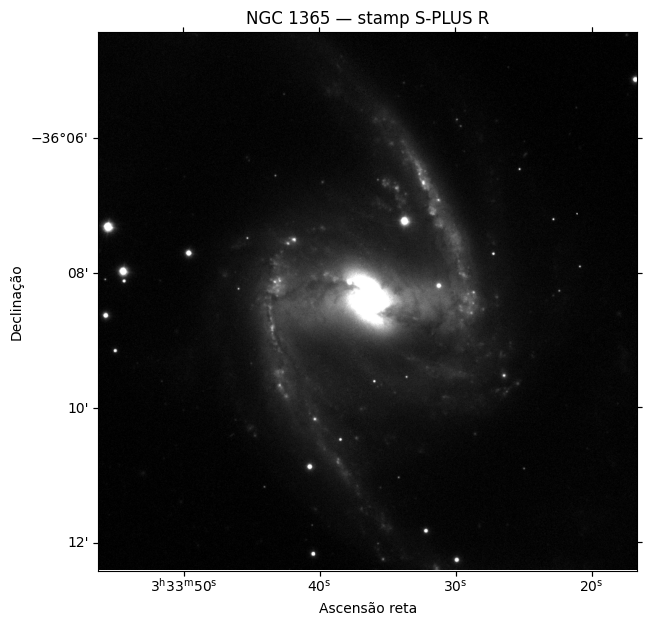

In [16]:
stamp_bytes = cl.create_stamp_by_coordinates(
    collection_id=collection_id, ra=RA, dec=DEC, size=SIZE_ARCMIN,
    filter="R", size_unit="arcmin", format="fits", pattern="swp.",
)
with fits.open(BytesIO(stamp_bytes)) as hdul:
    hdu = next(h for h in hdul if h.data is not None)
    stamp = hdu.data.copy()
    stamp_wcs = WCS(hdu.header).celestial

lo, hi = np.nanpercentile(stamp, [5, 99.5])
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": stamp_wcs})
ax.imshow(stamp, origin="lower", cmap="gray", vmin=lo, vmax=hi)
ax.set(title="NGC 1365 — stamp S-PLUS R", xlabel="Ascensão reta", ylabel="Declinação")
plt.show()


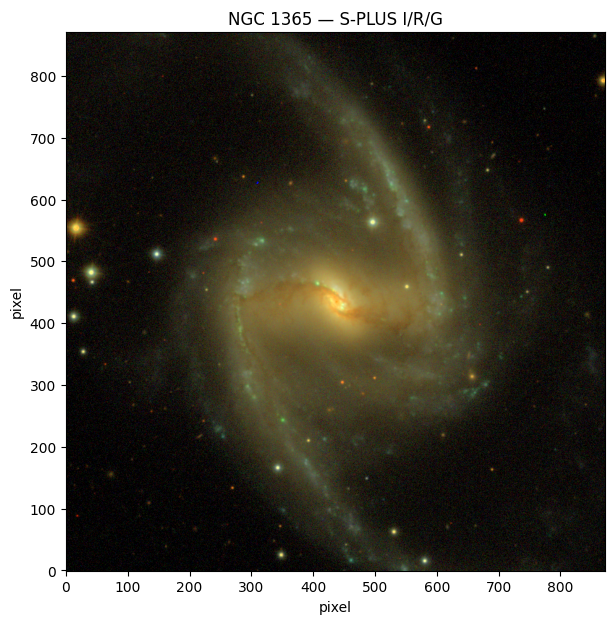

In [17]:
rgb_bytes = cl.create_rgb_image_by_coordinates(
    collection_id=collection_id, ra=RA, dec=DEC, size=SIZE_ARCMIN,
    r_filter="I", g_filter="R", b_filter="G", size_unit="arcmin",
    pattern="swp.",
)
rgb = Image.open(BytesIO(rgb_bytes))
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(rgb, origin="lower")
ax.set(title="NGC 1365 — S-PLUS I/R/G", xlabel="pixel", ylabel="pixel")
plt.show()


## Detecções S-PLUS DR4 sobre a imagem

A consulta usa um cone que cobre os cantos do stamp. O WCS do FITS transforma as coordenadas do catálogo em pixels da imagem.


Check query status at: https://ai-scope.cbpf.br/queries/522a85ca-cfef-439f-bd75-97fc796a7c80
Results fetched.
Detecções no cone: 171
Detecções dentro do stamp: 57


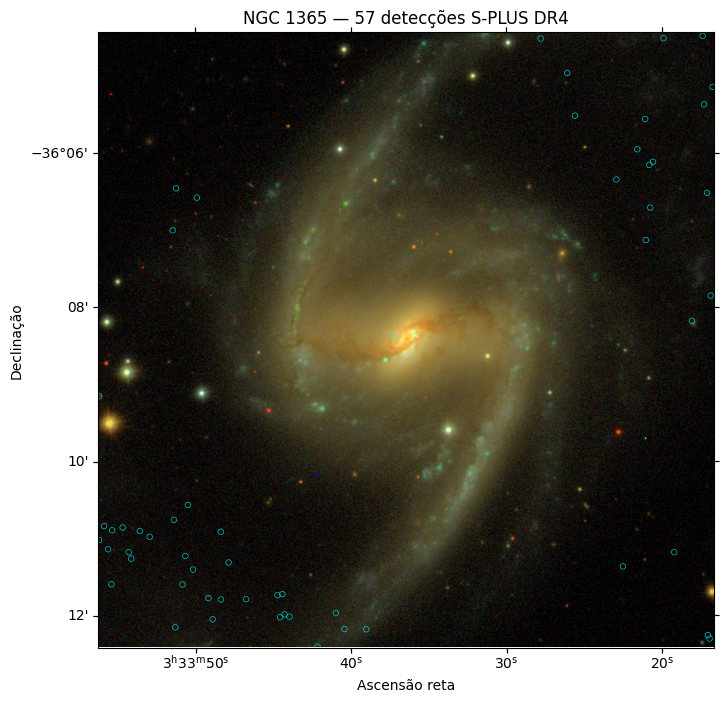

In [18]:
table = metadata.get_table("splus", "splus_dr4")
if table is None or not {"id", "ra", "dec", "r_auto"}.issubset(table.column_names()):
    raise RuntimeError("Tabela ou colunas esperadas de splus.splus_dr4 indisponíveis.")

radius_deg = SIZE_ARCMIN * np.sqrt(2) / 2 / 60  # meio da diagonal do stamp
query = f"""
SELECT id, ra, dec, r_auto
FROM splus.splus_dr4
WHERE cone(ra, dec, {RA}, {DEC}, {radius_deg})
"""
detections = cl.query_and_wait(query_text=query, mode="astroql").data
print(f"Detecções no cone: {len(detections)}")

if rgb.size != stamp.shape[::-1]:
    raise ValueError("RGB e stamp R têm dimensões diferentes; confira a cobertura.")
x, y = stamp_wcs.world_to_pixel_values(
    detections["ra"].to_numpy(dtype=float),
    detections["dec"].to_numpy(dtype=float),
)
inside = (np.isfinite(x) & np.isfinite(y) & (x >= 0) & (x < stamp.shape[1])
          & (y >= 0) & (y < stamp.shape[0]))
print(f"Detecções dentro do stamp: {inside.sum()}")

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": stamp_wcs})
ax.imshow(rgb, origin="lower")
ax.scatter(x[inside], y[inside], s=16, facecolors="none", edgecolors="cyan",
           linewidths=0.5, alpha=0.75)
ax.set(title=f"NGC 1365 — {inside.sum()} detecções S-PLUS DR4",
       xlabel="Ascensão reta", ylabel="Declinação")
plt.show()
